In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

In [2]:
color_map = {
    "NMPs": "orange",
    "NeuralTube": "skyblue",
    "Somite": "green",
    "Endoderm": "yellow",
    "Endothelial": "blue",
    "PGCLC": "purple",
    "MP": "pink",
    "NMSTD": "cyan",
    "NMSD": "gold",
    "NMS": "brown",
    "NS": "lightcoral",
    "?": "red"
}

In [3]:
def plot_differentiation_tree(
    diff_T,
    birth_rates=None,
    death_rates=None,
    transition_probabilities=None,
    show_labels=True,
    figsize=(6, 5),
):
    """
    Plot differentiation tree with optional birth/death rates and transition probabilities.
    
    Nodes: cell types (showing τ, b, d)
    Edges: differentiation paths (showing transition probabilities)
    """
    diff_T = diff_T.copy()  # avoid modifying original graph
    plt.figure(figsize=figsize)
    pos = nx.nx_agraph.graphviz_layout(diff_T, prog="dot")

    # Node labels
    node_labels = {}
    for n in diff_T.nodes:
        label = f"{n}"
        if diff_T.nodes[n].get("diff_time") is not None:
            label += f"\nτ={diff_T.nodes[n]['diff_time']:.2f}"
        if diff_T.nodes[n].get("diff_times") is not None:
            times_str = ", ".join(f"{t:.2f}" for t in diff_T.nodes[n]["diff_times"] if t is not None)
            if times_str:
                label += f"\nτs=[{times_str}]"
        if birth_rates is not None:
            label += f"\n$\\mu_b$={birth_rates.get(n, 0):.2f}"
        if death_rates is not None:
            label += f"\n$\\mu_d$={death_rates.get(n, 0):.2f}"
        node_labels[n] = label

    # Edge labels (transition probabilities)
    edge_labels = {}
    if transition_probabilities is not None:
        for u, v in diff_T.edges:
            prob = transition_probabilities.loc[u, v] if (
                u in transition_probabilities.index and v in transition_probabilities.columns
            ) else 0.0
            edge_labels[(u, v)] = f"{prob:.3f}"

    # Node colors
    node_colors = [color_map.get(n, "lightblue") if color_map else "lightblue" for n in diff_T.nodes()]

    # Draw tree
    nx.draw(
        diff_T,
        pos,
        with_labels=False,
        node_size=900,
        node_color=node_colors,
        arrows=True
    )

    # Draw node labels (smaller font)
    if show_labels:
        nx.draw_networkx_labels(
            diff_T,
            pos,
            labels=node_labels,
            font_size=8,       # smaller font
            font_color="black"
        )

        # Draw edge labels (red, smaller)
        if transition_probabilities is not None:
            nx.draw_networkx_edge_labels(
                diff_T,
                pos,
                edge_labels=edge_labels,
                font_size=7,
                font_color="red"
            )

    plt.axis("off")
    plt.tight_layout()
    plt.show()



In [4]:
states = [
    "MP",          # 0
    "NMSTD",       # 1
    "NMSD",        # 2
    "NMS",         # 3
    "NS",          # 4
    "PGCLC",       # 5
    "Endothelial", # 6
    "Endoderm",    # 7
    "NMPs",        # 8
    "Somite",      # 9
    "NeuralTube",  # 10
]

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_35027/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


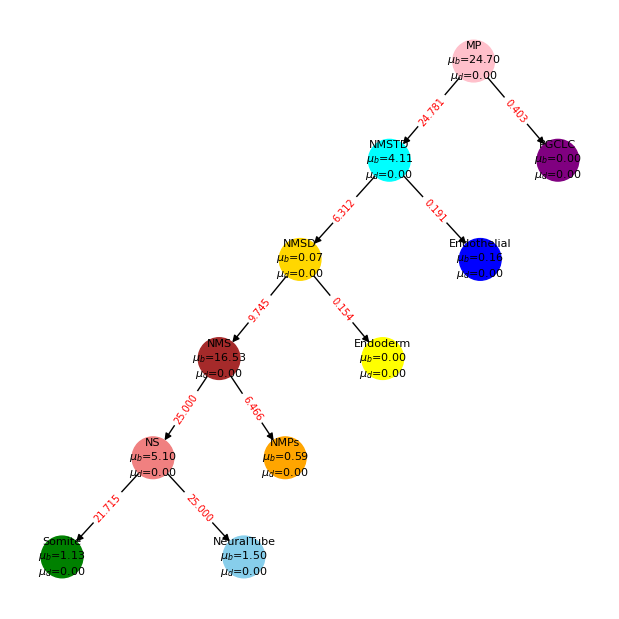

In [5]:
import pandas as pd
import networkx as nx

birth_rates = {
    "MP": 24.7042,
    "NMSTD": 4.1086,
    "NMSD": 0.0716978,
    "NMS": 16.5337,
    "NS": 5.10353,
    "PGCLC": 0.000411296,
    "Endothelial": 0.159831,
    "Endoderm": 2.38705e-19,
    "NMPs": 0.588271,
    "Somite": 1.12932,
    "NeuralTube": 1.49818,
}

death_rates = {s: 0.0 for s in states}

transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.781
transition_probabilities.loc["MP", "PGCLC"] = 0.403167

transition_probabilities.loc["NMSTD", "NMSD"] = 6.3121
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.190998

transition_probabilities.loc["NMSD", "NMS"] = 9.74486
transition_probabilities.loc["NMSD", "Endoderm"] = 0.154177

transition_probabilities.loc["NMS", "NS"] = 25.0
transition_probabilities.loc["NMS", "NMPs"] = 6.46594

transition_probabilities.loc["NS", "Somite"] = 21.7152
transition_probabilities.loc["NS", "NeuralTube"] = 25.0

diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [6]:
birth_rates = {
    "MP": 23.9759,
    "NMSTD": 4.09732,
    "NMSD": 0.130886,
    "NMS": 17.3294,
    "NS": 5.03826,
    "PGCLC": 0.000388197,
    "Endothelial": 0.142379,
    "Endoderm": 2.60315e-19,
    "NMPs": 0.635451,
    "Somite": 1.13431,
    "NeuralTube": 1.51277,
}

death_rates = {
    "MP": 0.000559402,
    "NMSTD": 0.00330822,
    "NMSD": 0.0018928,
    "NMS": 0.0349011,
    "NS": 0.108698,
    "PGCLC": 0.000281347,
    "Endothelial": 0.128546,
    "Endoderm": 2.60045e-21,
    "NMPs": 0.390091,
    "Somite": 0.250429,
    "NeuralTube": 0.24183,
}

transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.777
transition_probabilities.loc["MP", "PGCLC"] = 0.407213

transition_probabilities.loc["NMSTD", "NMSD"] = 6.34674
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.194776

transition_probabilities.loc["NMSD", "NMS"] = 11.2776
transition_probabilities.loc["NMSD", "Endoderm"] = 0.154118

transition_probabilities.loc["NMS", "NS"] = 24.9647
transition_probabilities.loc["NMS", "NMPs"] = 6.78439

transition_probabilities.loc["NS", "Somite"] = 22.3779
transition_probabilities.loc["NS", "NeuralTube"] = 24.9602

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_35027/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


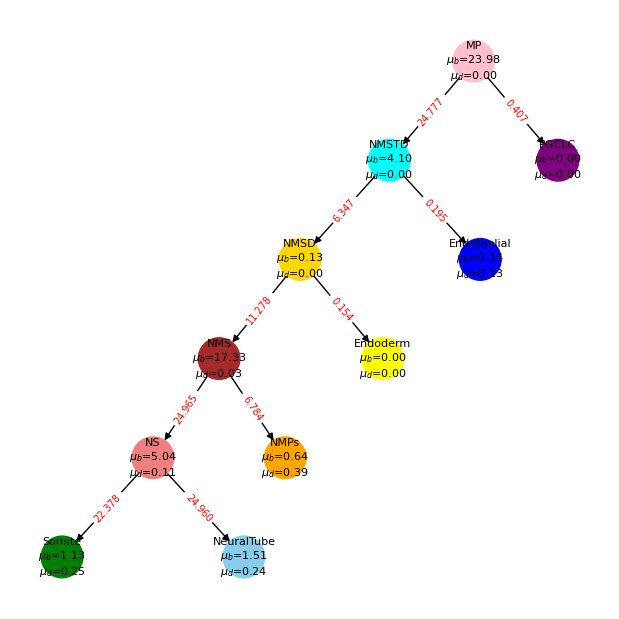

In [7]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [8]:
birth_rates = {
    "MP": 21.3237,
    "NMSTD": 6.71506,
    "NMSD": 0.850367,
    "NMS": 8.67734,
    "NS": 5.55869,
    "PGCLC": 0.000381738,
    "Endothelial": 0.28783,
    "Endoderm": 9.85104e-20,
    "NMPs": 1.48115,
    "Somite": 2.22852,
    "NeuralTube": 2.45521,
}

death_rates = {
    "MP": 0.000269655,
    "NMSTD": 0.000696743,
    "NMSD": 0.00206865,
    "NMS": 0.0359079,
    "NS": 0.0300526,
    "PGCLC": 0.000321475,
    "Endothelial": 0.0301534,
    "Endoderm": 6.05027e-38,
    "NMPs": 0.00280341,
    "Somite": 0.000926124,
    "NeuralTube": 9.53649e-19,
}

In [9]:
transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 24.7176
transition_probabilities.loc["MP", "PGCLC"] = 0.767406

transition_probabilities.loc["NMSTD", "NMSD"] = 9.23506
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.3916

transition_probabilities.loc["NMSD", "NMS"] = 2.29616
transition_probabilities.loc["NMSD", "Endoderm"] = 0.0397901

transition_probabilities.loc["NMS", "NS"] = 24.9337
transition_probabilities.loc["NMS", "NMPs"] = 3.69567

transition_probabilities.loc["NS", "Somite"] = 9.58776
transition_probabilities.loc["NS", "NeuralTube"] = 24.9816

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_35027/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


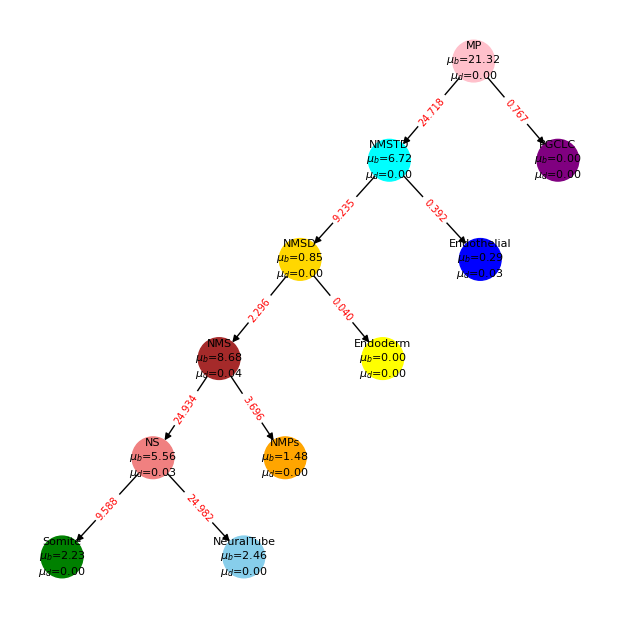

In [10]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

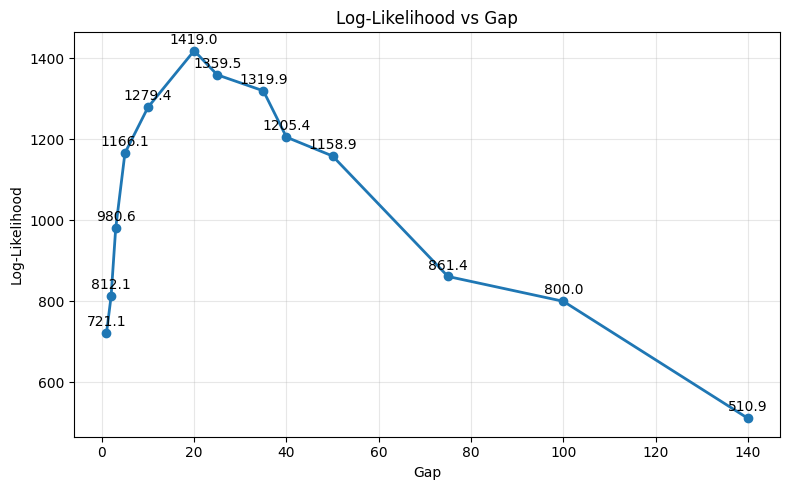

In [11]:
import matplotlib.pyplot as plt

gaps = [1, 2, 3, 5, 10, 20, 25, 35, 40, 50, 75, 100, 140]

log_likelihoods = [
    721.073157813475518,
    812.113545096103053,
    980.605571102539557,
    1166.139566163930112,
    1279.354109880308215,
    1418.992138690021193,
    1359.458355924292391,
    1319.866963629449174,
    1205.443759969694838,
    1158.877160625030456,
    861.368170642539894,
    799.991662830548535,
    510.932628119256890,
]

plt.figure(figsize=(8, 5))

plt.plot(gaps, log_likelihoods, marker="o", linewidth=2)

for x, y in zip(gaps, log_likelihoods):
    plt.annotate(
        f"{y:.1f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 5),
        ha="center"
    )

plt.xlabel("Gap")
plt.ylabel("Log-Likelihood")
plt.title("Log-Likelihood vs Gap")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
birth_rates = {
    "MP": 11.7946,
    "NMSTD": 3.67814,
    "NMSD": 1.93427,
    "NMS": 3.05602,
    "NS": 4.5584,
    "PGCLC": 0.000249368,
    "Endothelial": 0.195258,
    "Endoderm": 2.84011e-19,
    "NMPs": 3.693,
    "Somite": 5.43568,
    "NeuralTube": 4.0222,
}

death_rates = {
    "MP": 0.00159815,
    "NMSTD": 0.00678572,
    "NMSD": 0.000534289,
    "NMS": 0.00880009,
    "NS": 0.00027769,
    "PGCLC": 0.000211482,
    "Endothelial": 0.0611821,
    "Endoderm": 2.65723e-38,
    "NMPs": 1.06889e-17,
    "Somite": 0.000277877,
    "NeuralTube": 3.74186e-18,
}

In [13]:
transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["MP", "NMSTD"] = 1.51138
transition_probabilities.loc["MP", "PGCLC"] = 1.54492

transition_probabilities.loc["NMSTD", "NMSD"] = 1.66617
transition_probabilities.loc["NMSTD", "Endothelial"] = 0.867273

transition_probabilities.loc["NMSD", "NMS"] = 1.76979
transition_probabilities.loc["NMSD", "Endoderm"] = 1.21632

transition_probabilities.loc["NMS", "NS"] = 1.92956
transition_probabilities.loc["NMS", "NMPs"] = 0.842391

transition_probabilities.loc["NS", "Somite"] = 1.80087
transition_probabilities.loc["NS", "NeuralTube"] = 2.0328

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_35027/98870812.py:78: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


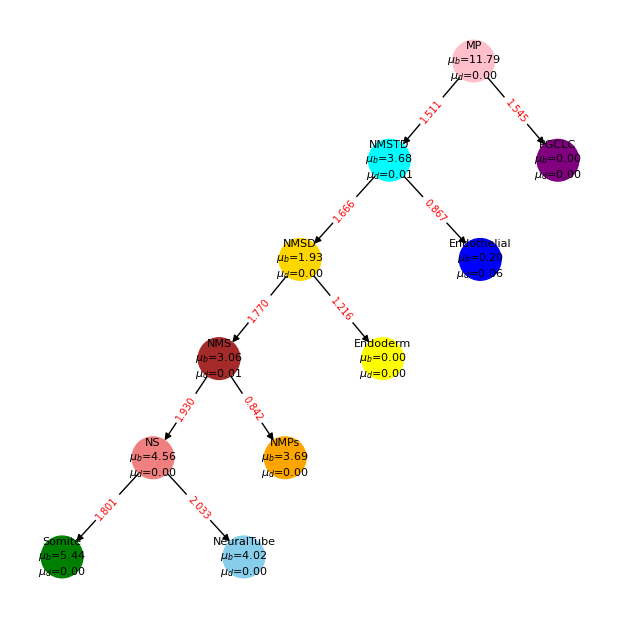

In [14]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("MP", "NMSTD"),
    ("MP", "PGCLC"),
    ("NMSTD", "NMSD"),
    ("NMSTD", "Endothelial"),
    ("NMSD", "NMS"),
    ("NMSD", "Endoderm"),
    ("NMS", "NS"),
    ("NMS", "NMPs"),
    ("NS", "Somite"),
    ("NS", "NeuralTube"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [15]:
import pandas as pd

states = ["T1", "L1", "L2", "L3", "S1"]

birth_rates = {
    "T1": 3.83098,
    "L1": 2.43285,
    "L2": 5.02467,
    "L3": 2.93942,
    "S1": 4.24620,
}

death_rates = {
    "T1": 1.73584e-08,
    "L1": 4.57656e-05,
    "L2": 5.11756e-07,
    "L3": 2.73071e-07,
    "S1": 1.25452e-07,
}

transition_probabilities = pd.DataFrame(
    0.0,
    index=states,
    columns=states,
)

transition_probabilities.loc["T1", "L1"] = 0.0192554
transition_probabilities.loc["T1", "L2"] = 0.0485814
transition_probabilities.loc["T1", "L3"] = 0.0192616
transition_probabilities.loc["T1", "S1"] = 0.010949

transition_probabilities.loc["L2", "T1"] = 0.174227
transition_probabilities.loc["L3", "T1"] = 0.170237

transition_probabilities.loc["S1", "T1"] = 0.198516
transition_probabilities.loc["S1", "L3"] = 1.65515e-08

print(transition_probabilities)

          T1        L1        L2            L3        S1
T1  0.000000  0.019255  0.048581  1.926160e-02  0.010949
L1  0.000000  0.000000  0.000000  0.000000e+00  0.000000
L2  0.174227  0.000000  0.000000  0.000000e+00  0.000000
L3  0.170237  0.000000  0.000000  0.000000e+00  0.000000
S1  0.198516  0.000000  0.000000  1.655150e-08  0.000000


In [16]:
def plot_differentiation_tree(
    diff_T,
    birth_rates=None,
    death_rates=None,
    transition_probabilities=None,
    show_labels=True,
    deflate_labels=False,
    figsize=(6, 5),
    color_map=None,
):
    """
    Plot differentiation tree with optional birth/death rates and transition probabilities.

    Reciprocal edges are drawn as separate curved arcs with separate labels.
    Self-loops are drawn as loops.
    """

    import matplotlib.pyplot as plt
    import networkx as nx
    import numpy as np

    diff_T = diff_T.copy()

    plt.figure(figsize=figsize)

    try:
        pos = nx.nx_agraph.graphviz_layout(diff_T, prog="dot")
    except Exception:
        pos = nx.spring_layout(diff_T, seed=42)

    # --------------------------------------------------
    # Node labels
    # --------------------------------------------------

    node_labels = {}

    for n in diff_T.nodes:
        label = f"{n}"

        if diff_T.nodes[n].get("diff_time") is not None:
            label += f"\nτ={diff_T.nodes[n]['diff_time']:.2f}"

        if diff_T.nodes[n].get("diff_times") is not None:
            times_str = ", ".join(
                f"{t:.2f}"
                for t in diff_T.nodes[n]["diff_times"]
                if t is not None
            )
            if times_str:
                label += f"\nτs=[{times_str}]"

        if deflate_labels:

            if birth_rates is not None:
                if f"{n}_0" in birth_rates:
                    label += f"\n$\\mu_b$={birth_rates[f'{n}_0']:.2f}"
                else:
                    label += f"\n$\\mu_b$={birth_rates.get(n, 0):.2f}"

            if death_rates is not None:
                if f"{n}_0" in death_rates:
                    label += f"\n$\\mu_d$={death_rates[f'{n}_0']:.2f}"
                else:
                    label += f"\n$\\mu_d$={death_rates.get(n, 0):.2f}"

        else:

            if birth_rates is not None:
                label += f"\n$\\mu_b$={birth_rates.get(n, 0):.2f}"

            if death_rates is not None:
                label += f"\n$\\mu_d$={death_rates.get(n, 0):.2f}"

        node_labels[n] = label

    # --------------------------------------------------
    # Edge labels
    # --------------------------------------------------

    edge_labels = {}

    if transition_probabilities is not None:

        if deflate_labels:

            for u, v in diff_T.edges:

                uc = f"{u}_0" if f"{u}_0" in transition_probabilities.index else u
                vc = f"{v}_0" if f"{v}_0" in transition_probabilities.columns else v

                prob = (
                    transition_probabilities.loc[uc, vc]
                    if (
                        uc in transition_probabilities.index
                        and vc in transition_probabilities.columns
                    )
                    else 0.0
                )

                edge_labels[(u, v)] = f"{prob:.3f}"

            for n in list(diff_T.nodes):

                if (
                    f"{n}_0" in transition_probabilities.index
                    and f"{n}_1" in transition_probabilities.columns
                ):
                    diff_T.add_edge(n, n)

                    edge_labels[(n, n)] = (
                        f"{transition_probabilities.loc[f'{n}_0', f'{n}_1']:.3f}"
                    )

        else:

            for u, v in diff_T.edges:

                prob = (
                    transition_probabilities.loc[u, v]
                    if (
                        u in transition_probabilities.index
                        and v in transition_probabilities.columns
                    )
                    else 0.0
                )

                edge_labels[(u, v)] = f"{prob:.3f}"

    # --------------------------------------------------
    # Node colors
    # --------------------------------------------------

    node_colors = [
        color_map.get(n, "lightblue") if color_map else "lightblue"
        for n in diff_T.nodes()
    ]

    # --------------------------------------------------
    # Draw nodes
    # --------------------------------------------------

    nx.draw_networkx_nodes(
        diff_T,
        pos,
        node_size=1200,
        node_color=node_colors,
    )

    # --------------------------------------------------
    # Draw edges
    # --------------------------------------------------

    edge_rads = {}

    for u, v in diff_T.edges():

        if u == v:
            rad = 0.6

        elif diff_T.has_edge(v, u):
            # opposite directions get opposite curvature
            rad = 0.35 if str(u) < str(v) else -0.35

        else:
            rad = 0.0

        edge_rads[(u, v)] = rad

        nx.draw_networkx_edges(
            diff_T,
            pos,
            edgelist=[(u, v)],
            arrows=True,
            arrowstyle="-|>",
            arrowsize=20,
            width=1.8,
            min_source_margin=15,
            min_target_margin=15,
            connectionstyle=f"arc3,rad={rad}",
        )

    # --------------------------------------------------
    # Node labels
    # --------------------------------------------------

    if show_labels:

        nx.draw_networkx_labels(
            diff_T,
            pos,
            labels=node_labels,
            font_size=8,
            font_color="black",
        )

    # --------------------------------------------------
    # Manual edge labels
    # --------------------------------------------------

    if show_labels and transition_probabilities is not None:

        for (u, v), label in edge_labels.items():

            x1, y1 = pos[u]
            x2, y2 = pos[v]

            rad = edge_rads[(u, v)]

            if u == v:

                plt.text(
                    x1,
                    y1 + 60,
                    label,
                    color="red",
                    fontsize=8,
                    ha="center",
                    va="center",
                    bbox=dict(
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.8,
                        pad=0.2,
                    ),
                )
                continue

            mx = (x1 + x2) / 2
            my = (y1 + y2) / 2

            dx = x2 - x1
            dy = y2 - y1

            norm = np.hypot(dx, dy)

            if norm > 0:

                # unit normal vector
                nxp = -dy / norm
                nyp = dx / norm

                # push label toward its curved arc
                offset = 80 * rad

                lx = mx + offset * nxp
                ly = my + offset * nyp

            else:
                lx = mx
                ly = my

            plt.text(
                lx,
                ly,
                label,
                color="red",
                fontsize=8,
                ha="center",
                va="center",
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.8,
                    pad=0.2,
                ),
            )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

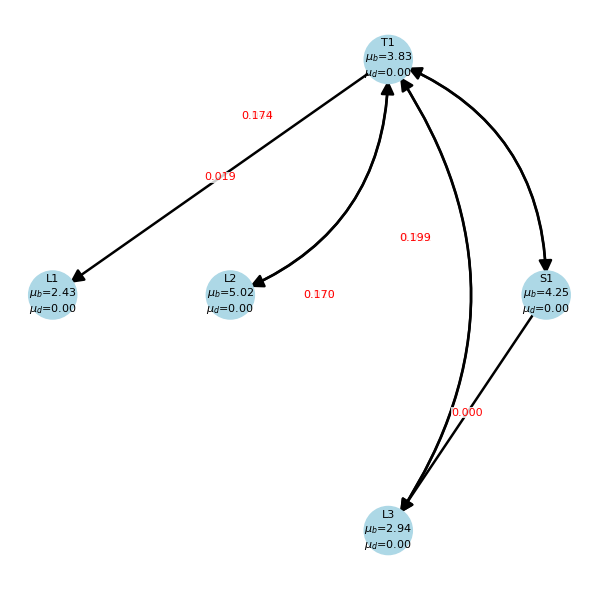

In [17]:
diff_T = nx.DiGraph()
diff_T.add_edges_from([
    ("T1", "L1"),
    ("T1", "L2"),
    ("T1", "L3"),
    ("T1", "S1"),

    ("L2", "T1"),
    ("L3", "T1"),

    ("S1", "T1"),
    ("S1", "L3"),
])

plot_differentiation_tree(
    diff_T,
    birth_rates=birth_rates,
    death_rates=death_rates,
    transition_probabilities=transition_probabilities,
    figsize=(6, 6),
)

In [18]:
lls = [
    -2422.53,
    -1502.31,
    -1129.93,
    -980.338,
    -865.797,
    -812.75,
    -823.408,
    -778.33,
    -785,
    -757.304,
    -747.989,
    -713.629,
    -721.777,
    -702.386,
    -624.63,
    -519.064,
    -418.059,
    -176.666,
]
k = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 25, 50, 100, 500]

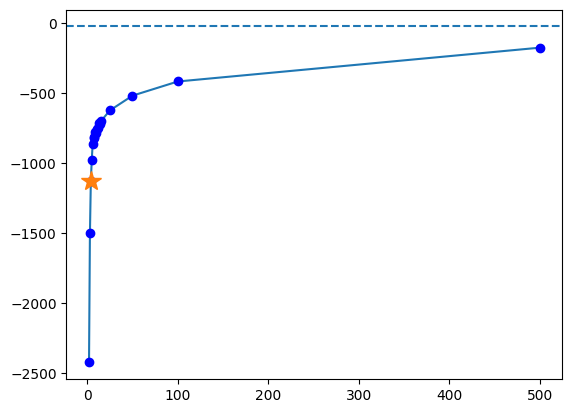

In [19]:
plt.plot(k, lls)
plt.plot(k, lls, 'o', color='blue')
plt.plot(4, -1129.93, marker='*', markersize=15)

plt.axhline(-25.5489, linestyle='--')
plt.show()

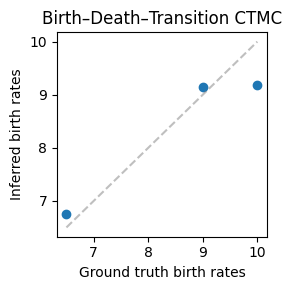

In [20]:
import matplotlib.pyplot as plt

# Ground truth birth rates (x-axis)
x = [6.5, 9.0, 10.0]

# Inferred birth rates (y-axis)
y = [6.75255, 9.13732, 9.17965]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# Optional: add y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', alpha=0.5, color='grey')

plt.xlabel("Ground truth birth rates")
plt.ylabel("Inferred birth rates")
plt.title("Birth–Death–Transition CTMC")


plt.tight_layout()
plt.show()

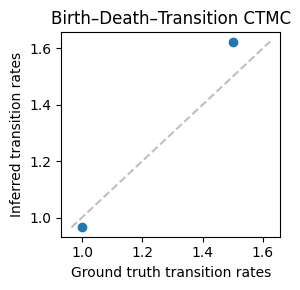

In [21]:
import matplotlib.pyplot as plt

# Ground truth transition rates (x-axis)
x = [1.0, 1.5]

# Inferred transition rates (y-axis)
y = [0.964794, 1.62399]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# Optional: y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', alpha=0.5, color='grey')

plt.xlabel("Ground truth transition rates")
plt.ylabel("Inferred transition rates")
plt.title("Birth–Death–Transition CTMC")

plt.tight_layout()
plt.show()

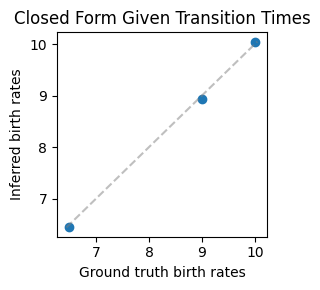

In [22]:
import matplotlib.pyplot as plt

# Ground truth birth rates (x-axis)
x = [6.5, 9.0, 10.0]

# Inferred birth rates (y-axis)
y = [6.44237, 8.94254, 10.0461]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', alpha=0.5, color='grey')

plt.xlabel("Ground truth birth rates")
plt.ylabel("Inferred birth rates")
plt.title("Closed Form Given Transition Times")

plt.tight_layout()
plt.show()

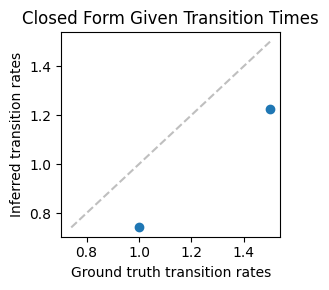

In [23]:
import matplotlib.pyplot as plt

# Ground truth transition rates (x-axis)
x = [1.0, 1.5]

# Inferred transition rates (y-axis)
y = [0.741528, 1.22339]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', color='grey', alpha=0.5)

plt.xlabel("Ground truth transition rates")
plt.ylabel("Inferred transition rates")
plt.title("Closed Form Given Transition Times")

plt.tight_layout()
plt.show()

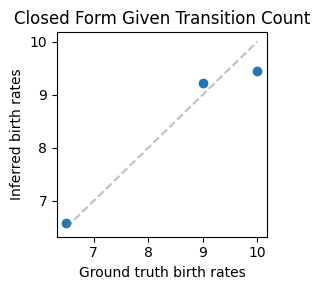

In [24]:
import matplotlib.pyplot as plt

# Ground truth birth rates (x-axis)
x = [6.5, 9.0, 10.0]

# Inferred birth rates (y-axis)
y = [6.58312, 9.22476, 9.45447]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', alpha=0.5, color='grey')

plt.xlabel("Ground truth birth rates")
plt.ylabel("Inferred birth rates")
plt.title("Closed Form Given Transition Count")

plt.tight_layout()
plt.show()

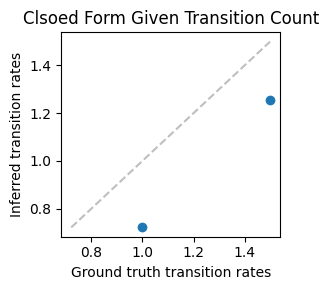

In [25]:
import matplotlib.pyplot as plt

# Ground truth transition rates (x-axis)
x = [1.0, 1.5]

# Inferred transition rates (y-axis)
y = [0.720812, 1.25346]

plt.figure(figsize=(3, 3))
plt.scatter(x, y)

# y = x reference line
xmin = min(min(x), min(y))
xmax = max(max(x), max(y))
plt.plot([xmin, xmax], [xmin, xmax], '--', alpha=0.5, color='grey')

plt.xlabel("Ground truth transition rates")
plt.ylabel("Inferred transition rates")
plt.title("Clsoed Form Given Transition Count")

plt.tight_layout()
plt.show()

In [26]:
filepaths = [f"../data/simulation/bdt_ctmc/test_{i}/inference.out" for i in range(25)]

filepaths_given = [f"../data/simulation/bdt_ctmc/test_{i}/inference.giventimes.out" for i in range(25)]

In [27]:
import re
import numpy as np
import matplotlib.pyplot as plt

def plot_birth_rates_from_filepaths(filepaths, title="Birth Rates"):

    # Ground truth birth rates
    ground_truth = [6.5, 9.0, 10.0]

    plt.figure(figsize=(5, 5))

    all_gt = []
    all_inferred = []

    for filepath in filepaths:

        with open(filepath) as f:
            text = f.read()

        # Use the last birth: line in the file
        matches = re.findall(r"birth:\s+([^\n]+)", text)
        if not matches:
            print(f"Skipping {filepath}: no birth rates found")
            continue

        inferred = [float(x) for x in matches[-1].split()]

        if len(inferred) != len(ground_truth):
            raise ValueError(
                f"{filepath}: found {len(inferred)} birth rates "
                f"but expected {len(ground_truth)}"
            )

        plt.scatter(
            ground_truth,
            inferred,
            color="blue"
        )

        all_gt.extend(ground_truth)
        all_inferred.extend(inferred)

    # y = x reference line
    all_vals = all_gt + all_inferred
    xmin = min(all_vals)
    xmax = max(all_vals)

    plt.plot(
        [xmin, xmax],
        [xmin, xmax],
        "--",
        color="grey",
        alpha=0.5,
        label="y = x"
    )

    # R^2 relative to y = x
    y_true = np.array(all_gt)
    y_pred = np.array(all_inferred)

    ss_res = np.sum((y_pred - y_true) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot

    plt.text(
        0.05,
        0.95,
        rf"$R^2 = {r2:.4f}$",
        transform=plt.gca().transAxes,
        va="top",
        fontsize=12
    )

    plt.xlabel("Ground truth birth rates")
    plt.ylabel("Inferred birth rates")
    plt.title(title)
    plt.tight_layout()
    plt.show()

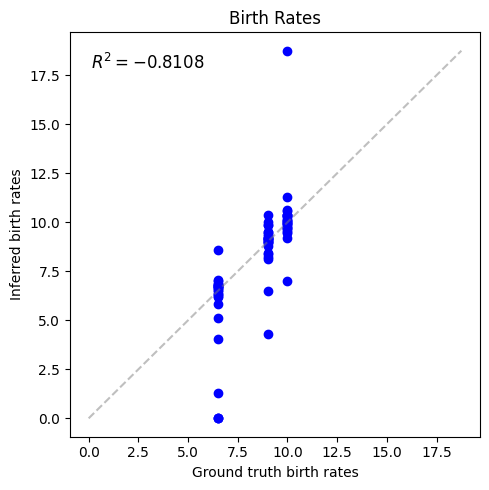

In [28]:
plot_birth_rates_from_filepaths(filepaths)

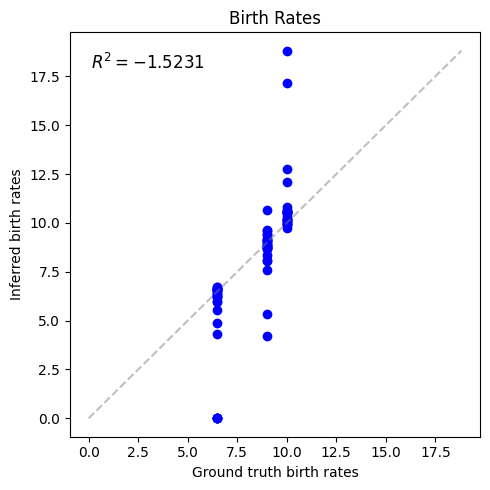

In [29]:
plot_birth_rates_from_filepaths(filepaths_given)

In [30]:
import re
import numpy as np
import matplotlib.pyplot as plt

def plot_transition_rates_from_filepaths(filepaths, title="Transition Rates"):

    # Ground truth transition rates
    ground_truth = [1.0, 1.5]

    plt.figure(figsize=(5, 5))

    all_gt = []
    all_inferred = []

    for filepath in filepaths:

        with open(filepath) as f:
            text = f.read()

        # Find transition block
        match = re.search(
            r"transitions:\s*\n(.*?)(?:\n[A-Za-z]+:|\Z)",
            text,
            re.DOTALL
        )

        if match is None:
            print(f"Skipping {filepath}: no transitions found")
            continue

        transition_block = match.group(1)

        # Extract rates from lines like:
        # 0->1 1.07606
        # 1->2 1.65017
        inferred = [
            float(rate)
            for _, rate in re.findall(
                r"(\d+->\d+)\s+([-+eE0-9.]+)",
                transition_block
            )
        ]

        if len(inferred) != len(ground_truth):
            raise ValueError(
                f"{filepath}: found {len(inferred)} transition rates "
                f"but expected {len(ground_truth)}"
            )

        plt.scatter(
            ground_truth,
            inferred,
            color="blue"
        )

        all_gt.extend(ground_truth)
        all_inferred.extend(inferred)

    if not all_gt:
        raise ValueError("No transition rates found.")

    # y = x reference line
    all_vals = all_gt + all_inferred
    xmin = min(all_vals)
    xmax = max(all_vals)

    plt.plot(
        [xmin, xmax],
        [xmin, xmax],
        "--",
        color="grey",
        alpha=0.5
    )

    # R² relative to y = x
    y_true = np.array(all_gt)
    y_pred = np.array(all_inferred)

    ss_res = np.sum((y_pred - y_true) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot

    plt.text(
        0.05,
        0.95,
        rf"$R^2 = {r2:.4f}$",
        transform=plt.gca().transAxes,
        va="top",
        fontsize=12
    )

    plt.xlabel("Ground truth transition rates")
    plt.ylabel("Inferred transition rates")
    plt.title(title)
    plt.tight_layout()
    plt.show()

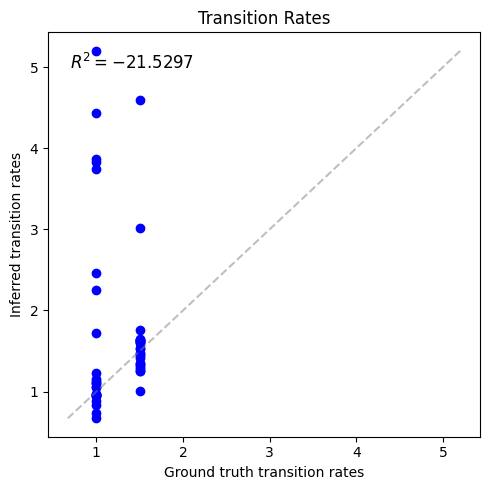

In [31]:
plot_transition_rates_from_filepaths(filepaths)

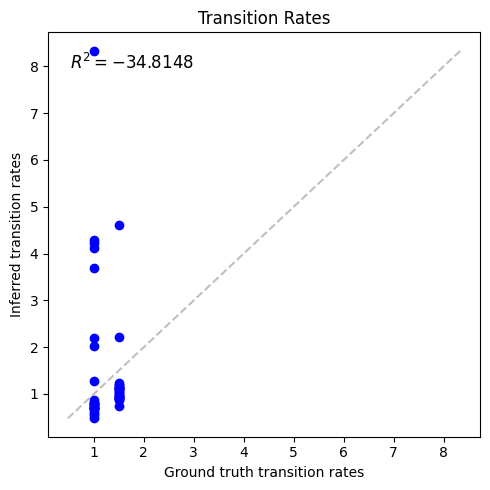

In [32]:
plot_transition_rates_from_filepaths(filepaths_given)

In [33]:
filepaths = [f"../data/simulation/bdt_ctmc/test_multi_{i}/inference.out" for i in range(5)]

filepaths_given = [f"../data/simulation/bdt_ctmc/test_multi_{i}/inference.giventimes.out" for i in range(5)]

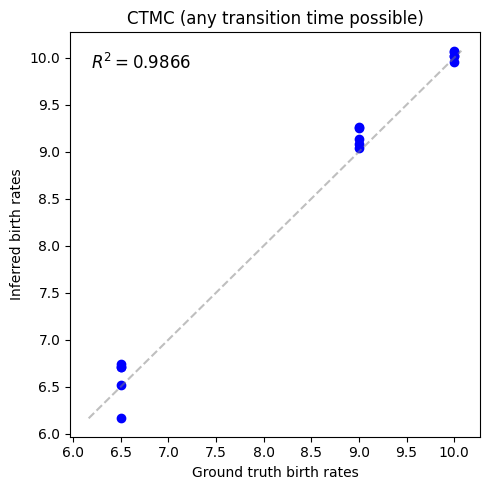

In [34]:
plot_birth_rates_from_filepaths(filepaths, "CTMC (any transition time possible)")

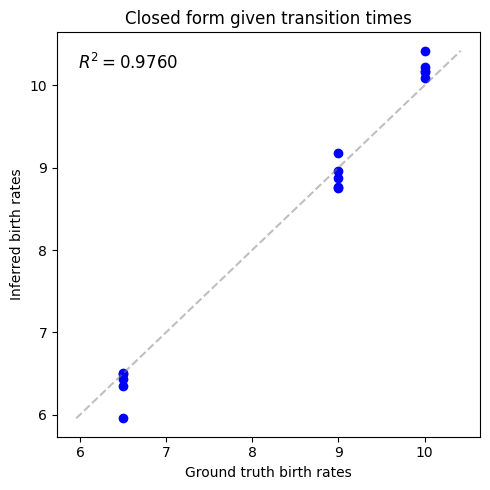

In [35]:
plot_birth_rates_from_filepaths(filepaths_given, "Closed form given transition times")

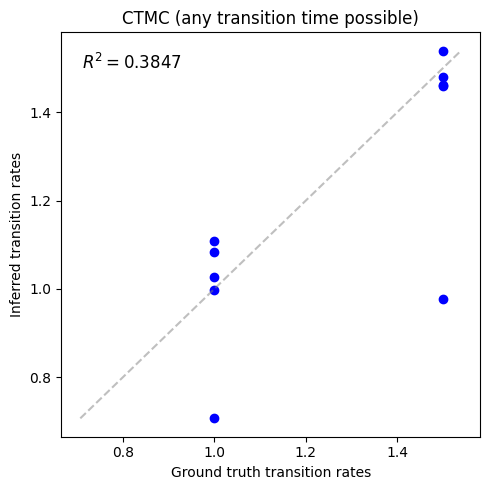

In [36]:
plot_transition_rates_from_filepaths(filepaths, "CTMC (any transition time possible)")

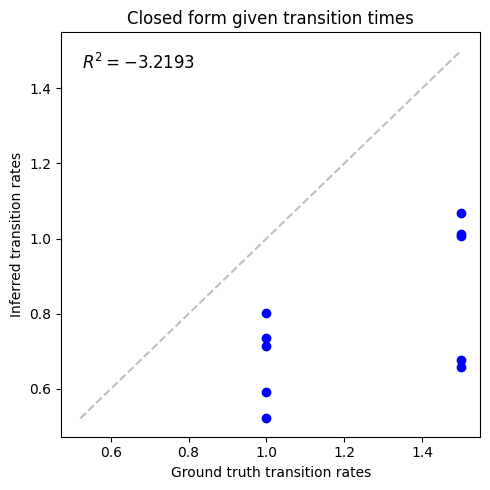

In [37]:
plot_transition_rates_from_filepaths(filepaths_given, "Closed form given transition times")

In [52]:
import re
import numpy as np
import matplotlib.pyplot as plt

def plot_transition_times_from_filepaths(
    filepaths,
    ground_truth=[0.6],
    title="Transition Times"
):

    plt.figure(figsize=(5, 5))

    all_gt = []
    all_inferred = []

    for filepath in filepaths:

        with open(filepath) as f:
            text = f.read()

        # Find transition_times block
        match = re.search(
            r"transition_times:\s*\n(.*?)(?:\n[A-Za-z]+:|\Z)",
            text,
            re.DOTALL
        )

        if match is None:
            print(f"Skipping {filepath}: no transition_times found")
            continue

        block = match.group(1).strip()

        inferred = []

        for line in block.splitlines():
            fields = line.split()

            if len(fields) < 2:
                continue

            inferred.append(float(fields[1]))

        if len(inferred) != len(ground_truth):
            raise ValueError(
                f"{filepath}: found {len(inferred)} transition times "
                f"but expected {len(ground_truth)}"
            )

        plt.scatter(
            ground_truth,
            inferred,
            color="blue"
        )

        all_gt.extend(ground_truth)
        all_inferred.extend(inferred)

    if not all_gt:
        raise ValueError("No transition times found.")

    all_gt = np.array(all_gt)
    all_inferred = np.array(all_inferred)

    # y = x reference line
    xmin = min(np.min(all_gt), np.min(all_inferred))
    xmax = max(np.max(all_gt), np.max(all_inferred))

    plt.plot(
        [0.5, 0.7],
        [0.5, 0.7],
        "--",
        color="grey",
        alpha=0.5
    )

    # R² relative to y=x
    ss_res = np.sum((all_inferred - all_gt) ** 2)
    ss_tot = np.sum((all_gt - np.mean(all_gt)) ** 2)

    if ss_tot > 0:
        r2 = 1 - ss_res / ss_tot
        plt.text(
            0.05,
            0.95,
            rf"$R^2 = {r2:.4f}$",
            transform=plt.gca().transAxes,
            va="top",
            fontsize=12
        )

    plt.xlabel("Ground truth transition times")
    plt.ylabel("Inferred transition times")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [60]:
filepaths = [f"../data/simulation/bdt_ctmc/test{i}_multi/inference.out" for i in range(6, 11)]


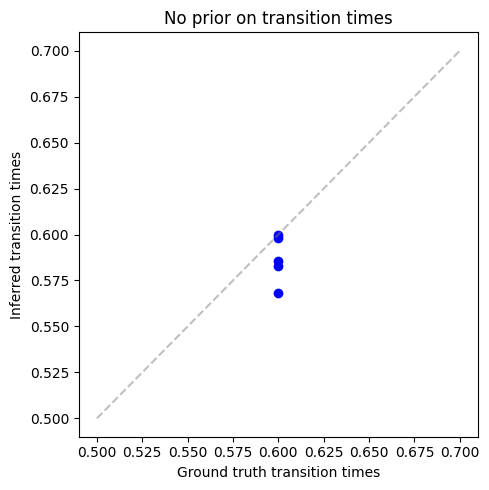

In [61]:
plot_transition_times_from_filepaths(filepaths, [0.6], "No prior on transition times")

In [58]:
filepaths = [f"../data/simulation/bdt_ctmc/test{i}_multi/inference.prior.out" for i in range(6, 11)]


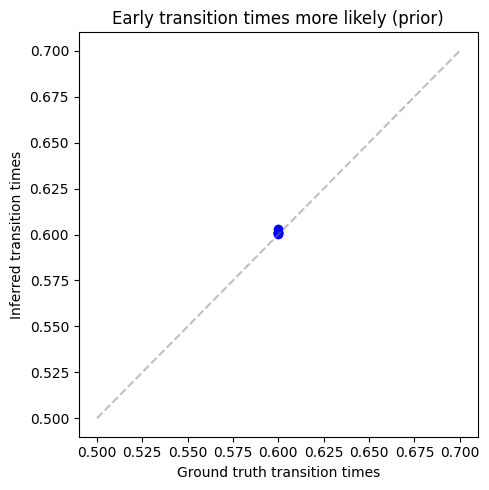

In [59]:
plot_transition_times_from_filepaths(filepaths, [0.6], "Early transition times more likely (prior)")